Solution found!
Number of moves: 2
(1, 2, 3)
(4, 0, 6)
(7, 5, 8)

(1, 2, 3)
(4, 5, 6)
(7, 0, 8)

(1, 2, 3)
(4, 5, 6)
(7, 8, 0)

Path: [(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (1, 4), (2, 4), (3, 4), (4, 4)]


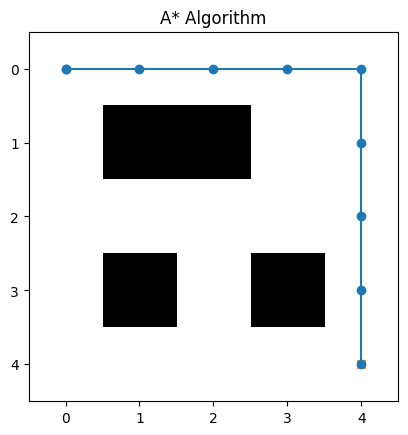

In [1]:
import heapq

goal = (1, 2, 3,
        4, 5, 6,
        7, 8, 0)

def heuristic(state):
    count = 0

    for i in range(9):
        if state[i] != 0 and state[i] != goal[i]:
            count += 1

    return count


def get_neighbors(state):
    neighbors = []

    blank = state.index(0)
    row = blank // 3
    col = blank % 3

    moves = [
        (-1, 0),   
        (1, 0),    
        (0, -1),  
        (0, 1)     
    ]

    for dr, dc in moves:
        new_row = row + dr
        new_col = col + dc

        if 0 <= new_row < 3 and 0 <= new_col < 3:
            new_blank = new_row * 3 + new_col

            new_state = list(state)

            new_state[blank], new_state[new_blank] = \
                new_state[new_blank], new_state[blank]

            neighbors.append(tuple(new_state))

    return neighbors


def a_star(start):
    pq = []

    h = heuristic(start)
    heapq.heappush(pq, (h, 0, start, [start]))

    visited = set()

    while pq:

        f, g, state, path = heapq.heappop(pq)

        if state == goal:
            return path

        if state in visited:
            continue

        visited.add(state)

        for next_state in get_neighbors(state):

            if next_state not in visited:
                new_g = g + 1
                new_h = heuristic(next_state)
                new_f = new_g + new_h

                heapq.heappush(
                    pq,
                    (new_f, new_g, next_state, path + [next_state])
                )

    return None


start = (1, 2, 3,
         4, 0, 6,
         7, 5, 8)

solution = a_star(start)

if solution:
    print("Solution found!")
    print("Number of moves:", len(solution) - 1)

    for state in solution:
        for i in range(0, 9, 3):
            print(state[i:i+3])
        print()
else:
    print("No solution found.")
    
    
    import heapq
import matplotlib.pyplot as plt

grid = [
    [0, 0, 0, 0, 0],
    [0, 1, 1, 0, 0],
    [0, 0, 0, 0, 0],
    [0, 1, 0, 1, 0],
    [0, 0, 0, 0, 0]
]

start = (0, 0)
goal = (4, 4)


def heuristic(a, b):
    return abs(a[0] - b[0]) + abs(a[1] - b[1])


def astar(grid, start, goal):

    rows = len(grid)
    cols = len(grid[0])

    open_list = []
    heapq.heappush(open_list, (0, start))

    came_from = {}

    g_score = {start: 0}

    f_score = {
        start: heuristic(start, goal)
    }

    directions = [
        (-1, 0),
        (1, 0),
        (0, -1),
        (0, 1)
    ]

    while open_list:

        current_f, current = heapq.heappop(open_list)

        if current == goal:

            path = []

            while current in came_from:
                path.append(current)
                current = came_from[current]

            path.append(start)
            path.reverse()

            return path

        for direction in directions:

            neighbor = (
                current[0] + direction[0],
                current[1] + direction[1]
            )

            if neighbor[0] < 0 or neighbor[0] >= rows:
                continue

            if neighbor[1] < 0 or neighbor[1] >= cols:
                continue

            if grid[neighbor[0]][neighbor[1]] == 1:
                continue

            new_g_score = g_score[current] + 1

            if neighbor not in g_score or new_g_score < g_score[neighbor]:

                came_from[neighbor] = current

                g_score[neighbor] = new_g_score

                f_score[neighbor] = (
                    new_g_score + heuristic(neighbor, goal)
                )

                heapq.heappush(
                    open_list,
                    (f_score[neighbor], neighbor)
                )

    return None


path = astar(grid, start, goal)

print("Path:", path)


plt.imshow(grid, cmap="gray_r")

if path:
    x = [point[1] for point in path]
    y = [point[0] for point in path]

    plt.plot(x, y, marker="o")

plt.scatter(start[1], start[0], marker="o")
plt.scatter(goal[1], goal[0], marker="x")

plt.title("A* Algorithm")
plt.show()

Path: [(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (1, 4), (2, 4), (3, 4), (4, 4)]


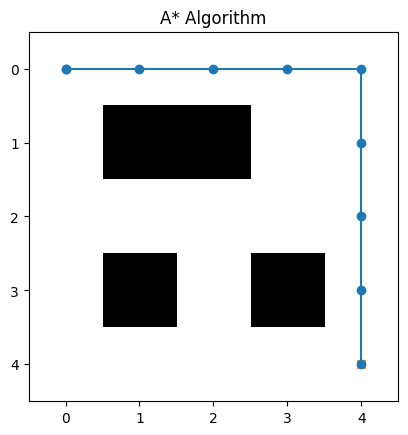

In [2]:
import heapq
import matplotlib.pyplot as plt

grid = [
    [0, 0, 0, 0, 0],
    [0, 1, 1, 0, 0],
    [0, 0, 0, 0, 0],
    [0, 1, 0, 1, 0],
    [0, 0, 0, 0, 0]
]

start = (0, 0)
goal = (4, 4)


def heuristic(a, b):
    return abs(a[0] - b[0]) + abs(a[1] - b[1])


def astar(grid, start, goal):

    rows = len(grid)
    cols = len(grid[0])

    open_list = []
    heapq.heappush(open_list, (0, start))

    came_from = {}

    g_score = {start: 0}

    f_score = {
        start: heuristic(start, goal)
    }

    directions = [
        (-1, 0),
        (1, 0),
        (0, -1),
        (0, 1)
    ]

    while open_list:

        current_f, current = heapq.heappop(open_list)

        if current == goal:

            path = []

            while current in came_from:
                path.append(current)
                current = came_from[current]

            path.append(start)
            path.reverse()

            return path

        for direction in directions:

            neighbor = (
                current[0] + direction[0],
                current[1] + direction[1]
            )

            if neighbor[0] < 0 or neighbor[0] >= rows:
                continue

            if neighbor[1] < 0 or neighbor[1] >= cols:
                continue

            if grid[neighbor[0]][neighbor[1]] == 1:
                continue

            new_g_score = g_score[current] + 1

            if neighbor not in g_score or new_g_score < g_score[neighbor]:

                came_from[neighbor] = current

                g_score[neighbor] = new_g_score

                f_score[neighbor] = (
                    new_g_score + heuristic(neighbor, goal)
                )

                heapq.heappush(
                    open_list,
                    (f_score[neighbor], neighbor)
                )

    return None


path = astar(grid, start, goal)

print("Path:", path)


plt.imshow(grid, cmap="gray_r")

if path:
    x = [point[1] for point in path]
    y = [point[0] for point in path]

    plt.plot(x, y, marker="o")

plt.scatter(start[1], start[0], marker="o")
plt.scatter(goal[1], goal[0], marker="x")

plt.title("A* Algorithm")
plt.show()
